# Model Exploration
- Inspect the Random Forest (RF) and convolutional neural network (CNN) used for three-class murmur classification.
- Compare shared inputs, validation tuning, training behavior and patient-level results.
- Use saved models and predictions; this notebook does not retrain models or overwrite their outputs.

#### Loading model outputs
- Run the training scripts from the project root if the saved models or prediction files are missing.
- The class order is shared by both models: Present, Absent and Unknown.
- Save every figure in reports/figures as a 300 DPI PNG before displaying it.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("dark_background")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import LABELS, SAMPLE_RATE, WINDOW_SECONDS, MIN_VALID_SECONDS
from src.evaluation.aggregate_patients import (
    KEYS, PROBS, aggregate_patients, metrics, validate_windows
)

OUTPUT_DIR = ROOT / "outputs"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_FILES = {"Random Forest": "rf", "CNN": "cnn"}
required_files = [
    "rf_model.joblib", "cnn_model.keras",
    "rf_window_predictions.csv", "cnn_window_predictions.csv",
    "rf_tuning_results.csv", "cnn_tuning_results.csv",
    "cnn_training_history.csv"
]
missing = [name for name in required_files if not (OUTPUT_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        "Missing model outputs: " + ", ".join(missing)
        + ". Run python -m src.models.train_rf and python -m src.models.train_cnn "
        + "from the project root."
    )

print("Output directory:", OUTPUT_DIR)
print("Class order:", LABELS)
print("Sample rate:", SAMPLE_RATE, "Hz")
print("Window length:", WINDOW_SECONDS, "seconds")
print("Minimum real audio per window:", MIN_VALID_SECONDS, "seconds")

Output directory: C:\Users\mikke\OneDrive\Documents\GitHub\heart-murmur-detection\outputs
Class order: ['Present', 'Absent', 'Unknown']
Sample rate: 4000 Hz
Window length: 4 seconds
Minimum real audio per window: 1.0 seconds


#### Shared windows and splits
- Both models use the same processed recordings and 4-second windows. The final window may contain zero padding; windows with less than 1 second of real audio are dropped.
- Split patients before training so recordings from one patient cannot appear in multiple splits.
- Count windows and patients separately because longer recordings contribute more windows.

In [2]:
window_predictions = {}
reference = None
for model_name, prefix in MODEL_FILES.items():
    predictions = pd.read_csv(
        OUTPUT_DIR / f"{prefix}_window_predictions.csv",
        dtype={"subject_id": str, "recording_id": str}
    )
    validate_windows(predictions)
    identities = (
        predictions[KEYS + ["split", "true_label"]]
        .sort_values(KEYS).reset_index(drop=True)
    )
    if reference is not None and not identities.equals(reference):
        raise ValueError("The models do not share the same windows, labels and splits.")
    reference = identities
    window_predictions[model_name] = predictions

windows = window_predictions["Random Forest"]
split_order = ["train", "val", "test"]
window_counts = pd.crosstab(windows["split"], windows["true_label"]).reindex(
    index=split_order, columns=LABELS, fill_value=0
)
patients = windows.drop_duplicates("subject_id")
patient_counts = pd.crosstab(patients["split"], patients["true_label"]).reindex(
    index=split_order, columns=LABELS, fill_value=0
)

print("Windows per split and label:")
display(window_counts)
print("Patients per split and label:")
display(patient_counts)
print("Patients appearing in multiple splits:",
      (windows.groupby("subject_id")["split"].nunique() > 1).sum())

Windows per split and label:


true_label,Present,Absent,Unknown
split,,,
train,2627,10039,671
val,486,2092,132
test,465,2211,108


Patients per split and label:


true_label,Present,Absent,Unknown
split,,,
train,125,486,48
val,27,104,10
test,27,105,10


Patients appearing in multiple splits: 0


#### Random Forest baseline
- Each window becomes 56 features: MFCC means and standard deviations, delta-MFCC statistics, RMS energy and zero-crossing-rate statistics.
- Compute these statistics from real audio only so padding does not change them.
- Class weights give rarer classes more influence. The implementation is in [train_rf.py](../src/models/train_rf.py).

In [3]:
from src.models.features import RF_FEATURE_NAMES

rf_model = joblib.load(OUTPUT_DIR / "rf_model.joblib")
rf_parameters = rf_model.get_params()
parameter_names = [
    "n_estimators", "max_depth", "min_samples_leaf",
    "class_weight", "random_state"
]
print("Input features:", rf_model.n_features_in_)
print("Output class indexes:", rf_model.classes_)
display(pd.Series(
    {name: rf_parameters[name] for name in parameter_names},
    name="Saved Random Forest settings"
).to_frame())

Input features: 56
Output class indexes: [0 1 2]


,Saved Random Forest settings
n_estimators,500
max_depth,None
min_samples_leaf,20
class_weight,balanced
random_state,42


#### Random Forest tuning
- Try combinations of tree count, maximum depth and minimum leaf size.
- Select the highest validation macro-F1 across all three classes. Training scores show how strongly each forest fits the training windows.
- A large training-to-validation gap suggests overfitting; the test set is excluded from the search.

,n_estimators,max_depth,min_samples_leaf,train_macro_f1,val_macro_f1
10,500,NaN,20,0.7764,0.4687
6,500,10.0,5,0.7983,0.4666
4,200,NaN,20,0.7712,0.4642
0,200,10.0,5,0.7938,0.4622
7,500,10.0,20,0.6686,0.4532
1,200,10.0,20,0.6692,0.4505
11,500,NaN,50,0.5867,0.4232
5,200,NaN,50,0.5841,0.4225
3,200,NaN,5,0.9944,0.4215
9,500,NaN,5,0.9966,0.4152


Selected validation macro-F1: 0.4687


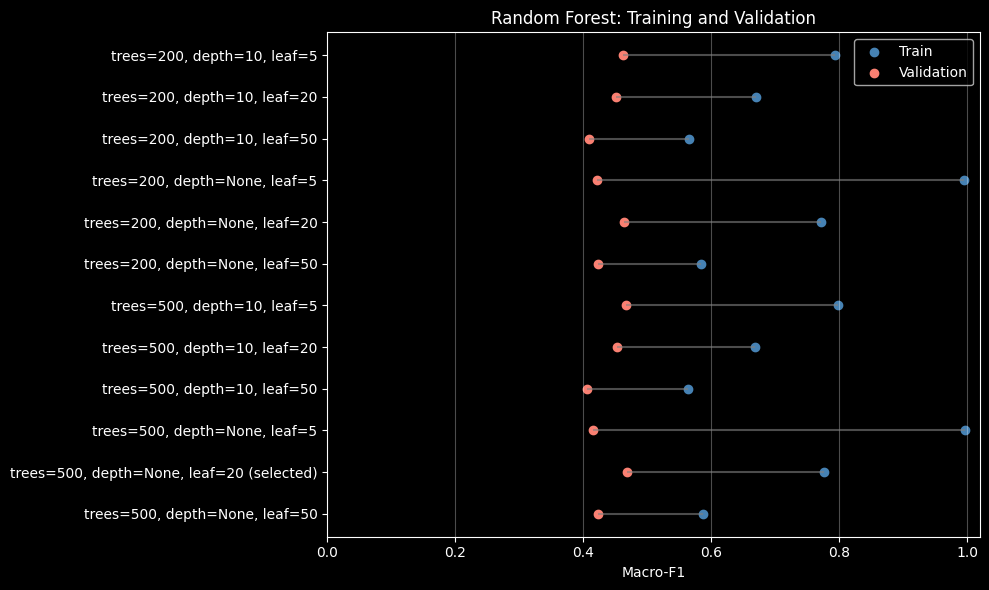

In [4]:
rf_tuning = pd.read_csv(OUTPUT_DIR / "rf_tuning_results.csv")
best_rf_index = rf_tuning["val_macro_f1"].idxmax()
best_rf = rf_tuning.loc[best_rf_index]
display(rf_tuning.sort_values("val_macro_f1", ascending=False).round(4))
print("Selected validation macro-F1:", round(best_rf["val_macro_f1"], 4))

setting_labels = [
    f"trees={int(row.n_estimators)}, "
    f"depth={'None' if pd.isna(row.max_depth) else int(row.max_depth)}, "
    f"leaf={int(row.min_samples_leaf)}"
    for row in rf_tuning.itertuples(index=False)
]
rows = np.arange(len(rf_tuning))
fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(rows, rf_tuning["val_macro_f1"], rf_tuning["train_macro_f1"],
          color="gray", alpha=0.6)
ax.scatter(rf_tuning["train_macro_f1"], rows, label="Train", color="steelblue")
ax.scatter(rf_tuning["val_macro_f1"], rows, label="Validation", color="salmon")
ax.set_yticks(rows, [
    label + (" (selected)" if index == best_rf_index else "")
    for index, label in enumerate(setting_labels)
])
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel("Macro-F1")
ax.set_title("Random Forest: Training and Validation")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_tuning_comparison.png", dpi=300)
plt.show()
plt.close(fig)

#### Random Forest feature importance
- Inspect the 15 features with the highest impurity-based importance in the saved forest.
- Correlated features can share importance. These values describe the fitted model and do not establish which audio characteristics cause murmurs.

,importance
zcr_mean,0.0677
mfcc_mean_3,0.0595
rms_mean,0.0505
mfcc_mean_1,0.0500
mfcc_mean_6,0.0334
zcr_std,0.0328
mfcc_mean_9,0.0320
mfcc_mean_4,0.0311
mfcc_mean_2,0.0309
mfcc_mean_7,0.0260


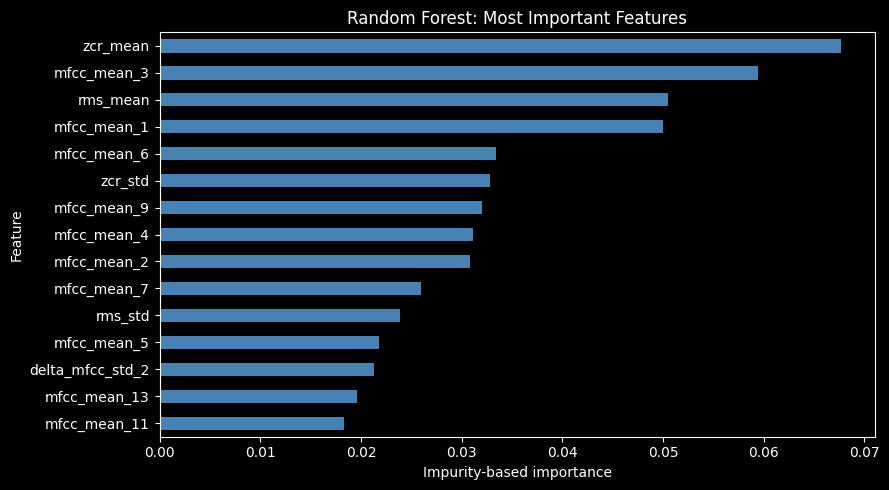

In [5]:
if rf_model.n_features_in_ != len(RF_FEATURE_NAMES):
    raise ValueError("Saved model features do not match the current feature names.")

feature_importance = pd.Series(
    rf_model.feature_importances_, index=RF_FEATURE_NAMES, name="importance"
).sort_values()
display(feature_importance.tail(15).sort_values(ascending=False).round(4).to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
feature_importance.tail(15).plot.barh(ax=ax, color="steelblue")
ax.set_title("Random Forest: Most Important Features")
ax.set_xlabel("Impurity-based importance")
ax.set_ylabel("Feature")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_feature_importance.png", dpi=300)
plt.show()
plt.close(fig)

#### CNN architecture
- The CNN receives a log-Mel spectrogram for each window: 64 Mel bands, 126 time frames and one channel.
- Three convolution and pooling blocks learn local patterns, followed by global average pooling, dropout and dense layers.
- The saved normalization layer uses training-data statistics. The final softmax returns probabilities in the shared class order.
- The implementation is in [train_cnn.py](../src/models/train_cnn.py).

In [6]:
from tensorflow import keras

cnn_model = keras.models.load_model(OUTPUT_DIR / "cnn_model.keras", compile=False)
print("Input shape:", cnn_model.input_shape)
print("Output shape:", cnn_model.output_shape)
print("Probability columns:", PROBS)
cnn_model.summary()

display(pd.DataFrame([
    {
        "Model": "Random Forest",
        "Input per window": f"{rf_model.n_features_in_} summary features",
        "Output": f"{len(LABELS)} class probabilities"
    },
    {
        "Model": "CNN",
        "Input per window": str(cnn_model.input_shape[1:]),
        "Output": f"{len(LABELS)} class probabilities"
    }
]))

Input shape: (None, 64, 126, 1)
Output shape: (None, 3)
Probability columns: ['prob_present', 'prob_absent', 'prob_unknown']


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_3 (Normalization) │ (None, 64, 126, 1)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 126, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 31, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 15, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,126 (395.03 KB)

 Trainable params: 101,123 (395.01 KB)

 Non-trainable params: 3 (16.00 B)

,Model,Input per window,Output
0,Random Forest,56 summary features,3 class probabilities
1,CNN,"(64, 126, 1)",3 class probabilities


#### Inspecting a model input
- Use one training window from the feature cache to inspect the CNN input and RF feature values.
- Cached log-Mel values are decibels relative to the loudest Mel-bin power in each window.
- If the cache is missing or its settings differ from the current feature code, skip this example. Build it separately with `python -m src.models.data_utils`.

Recording: 14241_AV
Patient label: Present
Real audio: 4.0 seconds
RF vector shape: (56,)
Log-Mel shape: (64, 126)


,feature_value
mfcc_mean_1,-377.850006
mfcc_mean_2,252.783997
mfcc_mean_3,-21.318001
mfcc_mean_4,-52.751999
mfcc_mean_5,17.584999
mfcc_mean_6,12.390000
mfcc_mean_7,-11.281000
mfcc_mean_8,-5.703000
mfcc_mean_9,-2.486000
mfcc_mean_10,-4.962000


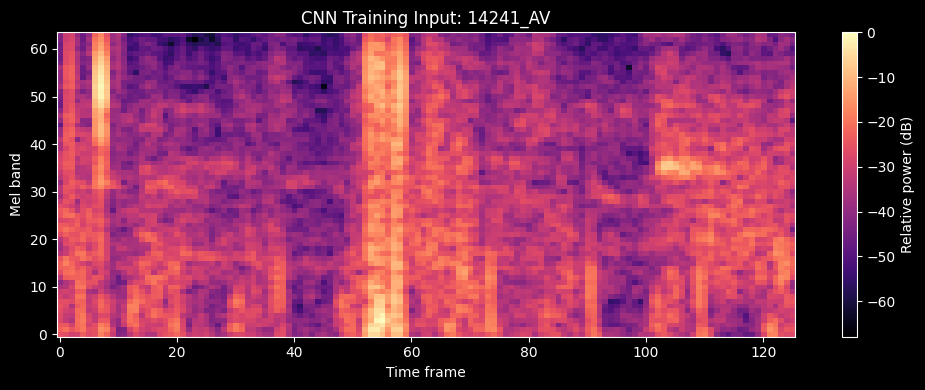

In [7]:
import json
from src.models.data_utils import cache_settings

cache_dir = ROOT / "data" / "processed" / "model_cache"
cache_files = ["windows.csv", "rf_features.npy", "log_mel.npy", "settings.json"]
cache_exists = all((cache_dir / name).exists() for name in cache_files)
cache_matches = (
    cache_exists
    and json.loads((cache_dir / "settings.json").read_text()) == cache_settings()
)

if cache_matches:
    cached_windows = pd.read_csv(cache_dir / "windows.csv", dtype={"subject_id": str})
    cached_rf = np.load(cache_dir / "rf_features.npy", mmap_mode="r")
    cached_mel = np.load(cache_dir / "log_mel.npy", mmap_mode="r")
    example_index = cached_windows.index[cached_windows["split"] == "train"][0]
    example = cached_windows.loc[example_index]
    print("Recording:", example["recording_id"])
    print("Patient label:", example["true_label"])
    print("Real audio:", example["valid_seconds"], "seconds")
    print("RF vector shape:", cached_rf[example_index].shape)
    print("Log-Mel shape:", cached_mel[example_index].shape)
    display(pd.Series(
        cached_rf[example_index], index=RF_FEATURE_NAMES, name="feature_value"
    ).head(13).round(3).to_frame())

    fig, ax = plt.subplots(figsize=(10, 4))
    mesh = ax.imshow(
        cached_mel[example_index].astype(np.float32),
        origin="lower", aspect="auto", cmap="magma"
    )
    ax.set_title("CNN Training Input: " + example["recording_id"])
    ax.set_xlabel("Time frame")
    ax.set_ylabel("Mel band")
    fig.colorbar(mesh, ax=ax, label="Relative power (dB)")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "cnn_log_mel_input.png", dpi=300)
    plt.show()
    plt.close(fig)
else:
    print("Matching feature cache not found; skipping the input example.")

#### CNN tuning
- Compare five settings, changing learning rate, batch size, convolution filters or dropout from a base configuration.
- Select the trial with the highest window-level validation macro-F1.
- Within each trial, early stopping monitors validation loss with patience 6 and restores the best epoch. Training is limited to 40 epochs.

,trial,learning_rate,batch_size,filters,dropout,epochs_run,best_epoch,val_macro_f1
3,4,0.0010,32,"(32, 64, 128)",0.3,24,18,0.5789
2,3,0.0010,64,"(16, 32, 64)",0.3,21,15,0.5494
0,1,0.0010,32,"(16, 32, 64)",0.3,10,4,0.5390
4,5,0.0010,32,"(16, 32, 64)",0.5,15,9,0.5199
1,2,0.0003,32,"(16, 32, 64)",0.3,19,13,0.5008


Selected trial: 4
Restored epoch: 18


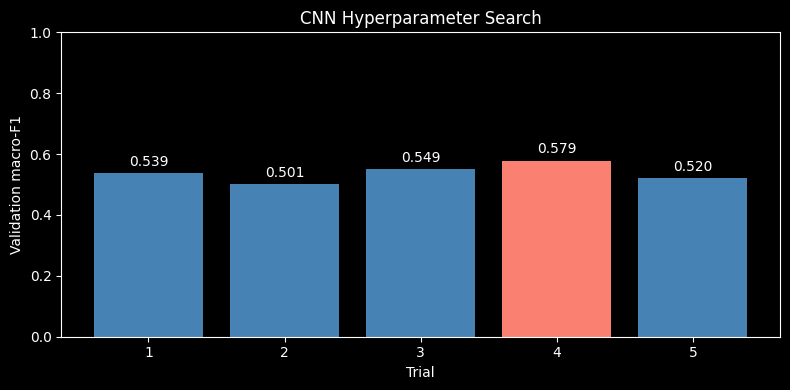

In [8]:
cnn_tuning = pd.read_csv(OUTPUT_DIR / "cnn_tuning_results.csv")
best_cnn_index = cnn_tuning["val_macro_f1"].idxmax()
best_cnn = cnn_tuning.loc[best_cnn_index]
display(cnn_tuning.sort_values("val_macro_f1", ascending=False).round(4))
print("Selected trial:", int(best_cnn["trial"]))
print("Restored epoch:", int(best_cnn["best_epoch"]))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    cnn_tuning["trial"].astype(str), cnn_tuning["val_macro_f1"],
    color=["salmon" if index == best_cnn_index else "steelblue"
           for index in cnn_tuning.index]
)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, 1)
ax.set_xlabel("Trial")
ax.set_ylabel("Validation macro-F1")
ax.set_title("CNN Hyperparameter Search")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "cnn_tuning_comparison.png", dpi=300)
plt.show()
plt.close(fig)

#### CNN training history
- Follow training and validation loss and accuracy for the selected trial.
- The dashed line marks the lowest validation loss; the saved model restores this epoch rather than the final epoch.
- Training loss uses class weights while validation loss does not, so their absolute values are not directly comparable.

Epochs run: 24
Restored epoch: 18


,epoch,loss,val_loss,accuracy,val_accuracy
17,18,0.6559,0.6156,0.6486,0.7472


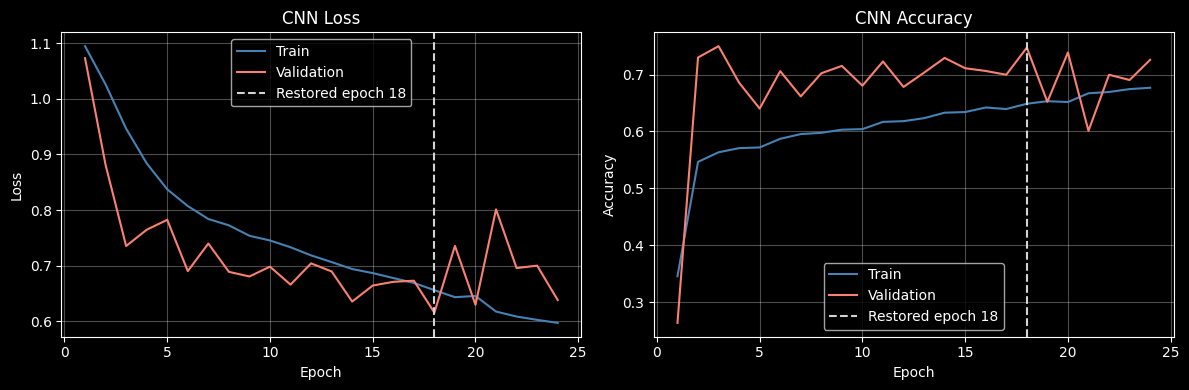

In [9]:
history = pd.read_csv(OUTPUT_DIR / "cnn_training_history.csv")
best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
print("Epochs run:", len(history))
print("Restored epoch:", best_epoch)
display(history.loc[history["epoch"] == best_epoch].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, train_column, val_column, title, ylabel in [
    (axes[0], "loss", "val_loss", "CNN Loss", "Loss"),
    (axes[1], "accuracy", "val_accuracy", "CNN Accuracy", "Accuracy")
]:
    ax.plot(history["epoch"], history[train_column], label="Train", color="steelblue")
    ax.plot(history["epoch"], history[val_column], label="Validation", color="salmon")
    ax.axvline(best_epoch, color="lightgray", linestyle="--",
               label=f"Restored epoch {best_epoch}")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "cnn_training_history.png", dpi=300)
plt.show()
plt.close(fig)

#### Window-level performance
- Each window inherits its patient's label, even when a murmur is not audible in that recording.
- Training scores are optimistic because the models were fitted to those windows. Validation macro-F1 was used for model selection.
- Macro-F1 gives Present, Absent and Unknown equal weight, regardless of their frequency.

In [10]:
from sklearn.metrics import accuracy_score, f1_score

window_rows = []
for model_name, predictions in window_predictions.items():
    for split in split_order:
        subset = predictions.loc[predictions["split"] == split]
        window_rows.append({
            "Model": model_name,
            "Split": split,
            "Windows": len(subset),
            "Accuracy": accuracy_score(subset["true_label"], subset["pred_label"]),
            "Macro F1": f1_score(
                subset["true_label"], subset["pred_label"],
                labels=LABELS, average="macro", zero_division=0
            )
        })
window_results = pd.DataFrame(window_rows)
display(window_results.round(4))

,Model,Split,Windows,Accuracy,Macro F1
0,Random Forest,train,13337,0.8548,0.7764
1,Random Forest,val,2710,0.6941,0.4687
2,Random Forest,test,2784,0.7101,0.4705
3,CNN,train,13337,0.7767,0.6354
4,CNN,val,2710,0.7472,0.5789
5,CNN,test,2784,0.7507,0.5544


#### From windows to patients
- Compare aggregation rules on validation patients using the existing aggregation helper.
- `window_mean` gives every window equal weight. `recording_mean` first averages windows within each recording, then gives each recording equal weight.
- The project uses `recording_mean` for both models. Keep this rule fixed when evaluating the test set.

In [11]:
validation_rows = []
for model_name, predictions in window_predictions.items():
    validation = predictions.loc[predictions["split"] == "val"]
    for method in ["window_mean", "recording_mean"]:
        aggregated = aggregate_patients(validation, method)
        scores = metrics(aggregated)
        validation_rows.append({
            "Model": model_name,
            "Method": method,
            "Patients": scores["n_subjects"],
            "Accuracy": scores["accuracy"],
            "Macro F1": scores["macro_f1"]
        })
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))
AGGREGATION_METHOD = "recording_mean"
print("Fixed test aggregation:", AGGREGATION_METHOD)

,Model,Method,Patients,Accuracy,Macro F1
0,Random Forest,window_mean,141,0.7730,0.5998
1,Random Forest,recording_mean,141,0.7801,0.6186
2,CNN,window_mean,141,0.8723,0.7733
3,CNN,recording_mean,141,0.8794,0.7842


Fixed test aggregation: recording_mean


#### Patient-level test comparison
- Apply the fixed aggregation rule to held-out test patients without retraining or changing model settings.
- Accuracy measures overall correctness. Macro precision, recall and F1 give equal weight to each class.
- Macro ROC-AUC averages one-vs-rest ROC-AUC across all three classes and uses probabilities rather than predicted labels.

,Patients,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
Model,,,,,,
Random Forest,142,0.7183,0.5410,0.5060,0.5197,0.7661
CNN,142,0.8239,0.6783,0.6873,0.6773,0.8962


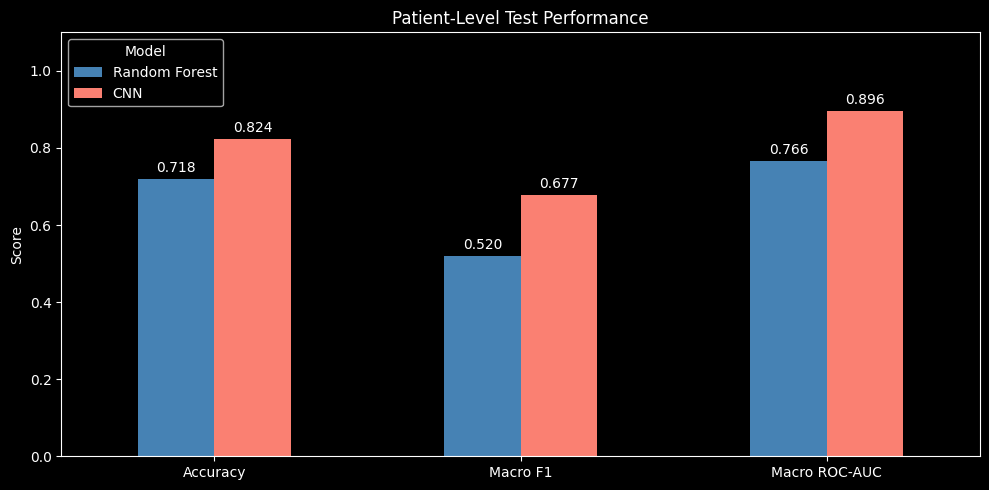

In [12]:
from sklearn.metrics import roc_auc_score

patient_predictions = {}
patient_rows = []
for model_name, predictions in window_predictions.items():
    test_windows = predictions.loc[predictions["split"] == "test"]
    test_patients = aggregate_patients(test_windows, AGGREGATION_METHOD)
    patient_predictions[model_name] = test_patients
    scores = metrics(test_patients)
    class_aucs = [
        roc_auc_score(
            test_patients["true_label"].eq(label),
            test_patients[probability_column]
        )
        for label, probability_column in zip(LABELS, PROBS)
    ]
    patient_rows.append({
        "Model": model_name,
        "Patients": scores["n_subjects"],
        "Accuracy": scores["accuracy"],
        "Macro Precision": np.mean([scores[f"precision_{label.lower()}"] for label in LABELS]),
        "Macro Recall": np.mean([scores[f"recall_{label.lower()}"] for label in LABELS]),
        "Macro F1": scores["macro_f1"],
        "Macro ROC-AUC": np.mean(class_aucs)
    })
patient_results = pd.DataFrame(patient_rows).set_index("Model")
display(patient_results.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
patient_results[["Accuracy", "Macro F1", "Macro ROC-AUC"]].T.plot.bar(
    ax=ax, rot=0, color=["steelblue", "salmon"]
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Patient-Level Test Performance")
ax.legend(title="Model")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "patient_model_comparison.png", dpi=300)
plt.show()
plt.close(fig)

#### Per-class errors
- Read confusion matrices with true labels on rows and predicted labels on columns.
- Inspect precision, recall and support for every class, especially Unknown, which has few patients.

precision  recall  f1-score  support
Model         Label                                        
Random Forest Present     0.3704  0.3704    0.3704     27.0
              Absent      0.8241  0.8476    0.8357    105.0
              Unknown     0.4286  0.3000    0.3529     10.0
CNN           Present     0.7826  0.6667    0.7200     27.0
              Absent      0.8952  0.8952    0.8952    105.0
              Unknown     0.3571  0.5000    0.4167     10.0

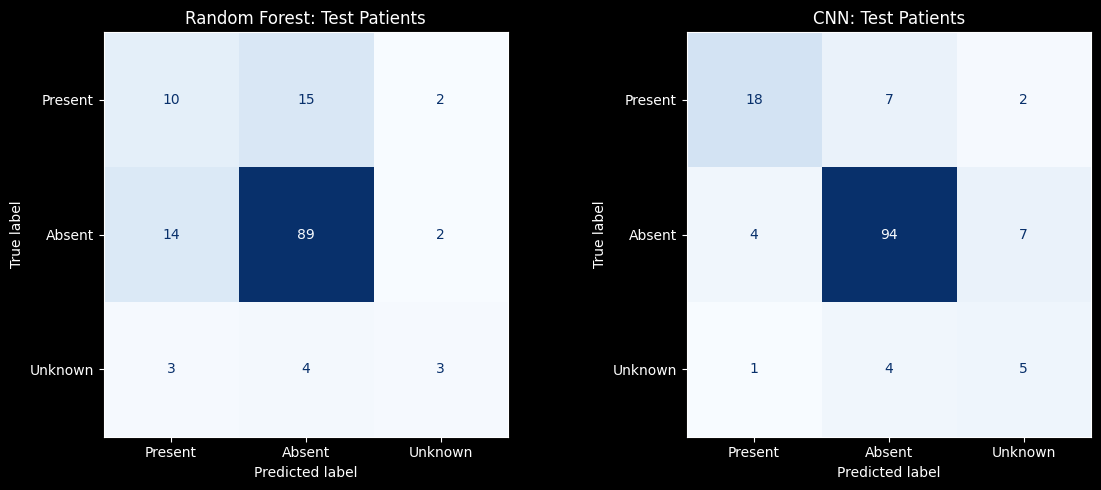

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

reports = {
    model_name: pd.DataFrame(classification_report(
        predictions["true_label"], predictions["pred_label"],
        labels=LABELS, output_dict=True, zero_division=0
    )).T.loc[LABELS]
    for model_name, predictions in patient_predictions.items()
}
display(pd.concat(reports, names=["Model", "Label"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (model_name, predictions) in zip(axes, patient_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        predictions["true_label"], predictions["pred_label"],
        labels=LABELS, display_labels=LABELS, cmap="Blues",
        values_format="d", colorbar=False, ax=ax
    )
    ax.set_title(model_name + ": Test Patients")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "patient_confusion_matrices.png", dpi=300)
plt.show()
plt.close(fig)

#### Patient-level ROC curves
- Treat each label as the positive class and the other two labels as negatives.
- Include the saved Logistic Regression predictions after running notebook 06.
- The diagonal is a random-classifier reference. Use these curves to describe the fixed models, without choosing settings from test results.

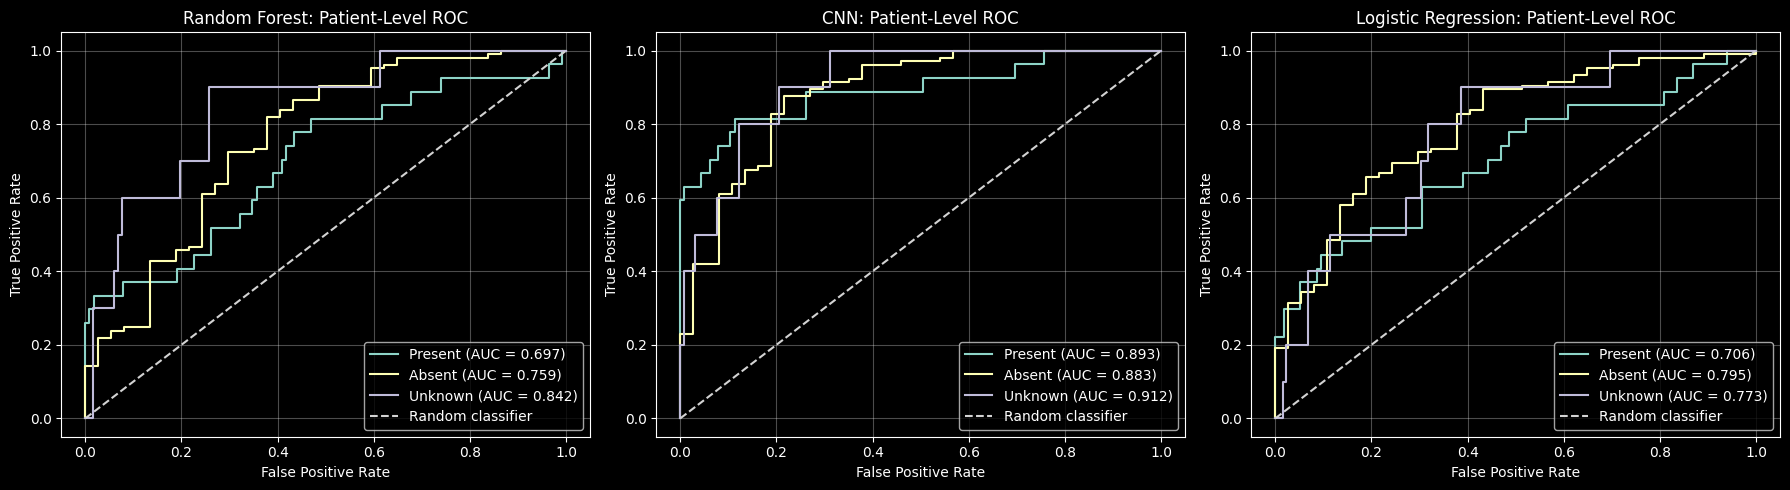

In [14]:
from sklearn.metrics import roc_curve, auc

roc_predictions = patient_predictions.copy()
logistic_path = OUTPUT_DIR / "additional_analysis" / "logistic_window_predictions.csv"
if logistic_path.is_file():
    logistic_windows = pd.read_csv(
        logistic_path, dtype={"subject_id": str, "recording_id": str}
    )
    logistic_identities = (
        logistic_windows[KEYS + ["split", "true_label"]]
        .sort_values(KEYS).reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(reference, logistic_identities)
    roc_predictions["Logistic Regression"] = aggregate_patients(
        logistic_windows.loc[logistic_windows["split"] == "test"], AGGREGATION_METHOD
    )
else:
    print("Run notebook 06 and rerun this cell to include Logistic Regression.")

fig, axes = plt.subplots(1, len(roc_predictions), figsize=(6 * len(roc_predictions), 5))
for ax, (model_name, predictions) in zip(axes, roc_predictions.items()):
    for label, probability_column in zip(LABELS, PROBS):
        fpr, tpr, _ = roc_curve(
            predictions["true_label"].eq(label),
            predictions[probability_column]
        )
        ax.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="lightgray", linestyle="--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(model_name + ": Patient-Level ROC")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "patient_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)

#### Model notes
- The models were tuned using window-level validation macro-F1; patient-level aggregation was compared separately on validation data.
- Patient labels can be noisy supervision for individual recordings and windows.
- A small Unknown class makes its metrics sensitive to a few errors. Read the class supports alongside aggregate scores.
- Results come from one patient split and one seed, without confidence intervals or repeated-run comparisons.